# PINNs(Physics-Informed Neural Networks)


Part 1: Classical Regression (Data-Driven) – Train a neural network using only a few experimental data points and observe its inability to extrapolate beyond the known domain.

Part 2: PINN for an ODE (Ordinary Differential Equation) – Incorporate the logistic equation and the initial condition into the loss function, allowing the model to make accurate predictions across the entire domain.

In [1]:
import torch
from torch import nn
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from matplotlib import cm

---
## Parte 1: Regressão  

1.1 Neural Network Architecture (simple_NN)

We begin by defining a Multilayer Perceptron (MLP) for one-dimensional problems. The network takes 1 input ($x$), passes it through 3 hidden layers (16 -> 32 -> 16 neurons), and returns 1 output ($y$).

In [2]:
class simple_NN(nn.Module):
    def __init__(self):
        super(simple_NN, self).__init__()
        self.linear_tanh_stack = nn.Sequential(
            nn.Linear(1, 16),
            nn.Tanh(),
            nn.Linear(16, 32),
            nn.Tanh(),
            nn.Linear(32, 16),
            nn.Tanh(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        out = self.linear_tanh_stack(x)
        return out

### 1.2 Data

In [3]:
x_train = torch.tensor([[1.1437e-04],
                        [1.4676e-01],
                        [3.0233e-01],
                        [4.1702e-01],
                        [7.2032e-01]], dtype=torch.float32)

y_train = torch.tensor([[1.0000],
                        [1.0141],
                        [1.0456],
                        [1.0753],
                        [1.1565]], dtype=torch.float32)

1.3 Supervised Training

The network is trained for 1000 epochs using the Adam optimizer ($lr = 0.01$) to minimize only the Mean Squared Error (MSE) between the model's predictions and the 5 training points:
$$\mathcal{L}_{dados} = \frac{1}{N} \sum_{i=1}^{N} \left( f_{NN}(x_i) - y_i \right)^2$$

In [4]:
model = simple_NN()
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

for ep in range(1000):
    pred = model(x_train)
    loss = loss_fn(pred, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if ep % 200 == 0:
        print(f"epoch: {ep}, loss: {loss.item():>7f}")

epoch: 0, loss: 1.244450
epoch: 200, loss: 0.000104
epoch: 400, loss: 0.000051
epoch: 600, loss: 0.000014
epoch: 800, loss: 0.000004


1.4 Evaluation and Extrapolation

We now evaluate the trained network over a wider domain: $x \in [0.0, 1.5]$ (100 uniformly spaced points).

In [5]:

domain = [0.0, 1.5]
x_eval = torch.linspace(domain[0], domain[1], steps=100).reshape(-1, 1)
f_eval = model(x_eval)

The plot below shows the typical result of a purely data-driven network: it fits the observed points perfectly, but becomes almost flat as soon as it moves beyond the known region.

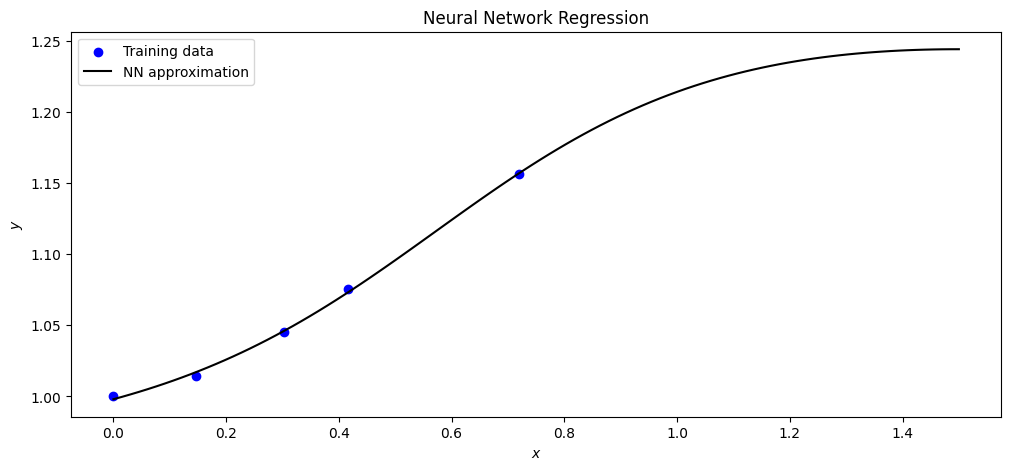

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(x_train.detach().numpy(), y_train.detach().numpy(), label="Training data", color="blue")
ax.plot(x_eval.detach().numpy(), f_eval.detach().numpy(), label="NN approximation", color="black")
ax.set(title="Neural Network Regression", xlabel="$x$", ylabel="$y$")
ax.legend();

---
## Part 2: Solving an Ordinary Differential Equation (ODE) with PINNs

To address the extrapolation problem, we teach the neural network the physical law governing the system — in this case, the following Ordinary Differential Equation (ODE) with an initial condition:
$$\frac{df(t)}{dt} = R \cdot t \cdot (1 - t), \qquad f(0) = 1.0$$

#Formulation of the Physics-Based Loss Function
The network is penalized not only for errors in the observed data, but also for violating the differential equation and the initial condition:
$$\mathcal{L}_{total} = \mathcal{L}_{PDE} + \mathcal{L}_{BC} + \mathcal{L}_{dados}$$


In [7]:
R = 1.0     # Parâmetro físico da equação
ft0 = 1.0   # Condição inicial: f(0) = 1.0

2.1 Automatic Differentiation (df)

The df function uses torch.autograd.grad to calculate exact derivatives of arbitrary order of the network output with respect to the input $x$. The create_graph=True argument ensures that the computational graph is preserved, allowing higher-order derivatives to be calculated and the network weights to be optimized during backpropagation.

In [8]:
def df(f: simple_NN, x: torch.Tensor = None, order: int = 1) -> torch.Tensor:
    """Calcula a derivada da rede neuronal em relação à variável de entrada x."""
    df_value = f(x)
    for _ in range(order):
        df_value = torch.autograd.grad(
            df_value,
            x,
            grad_outputs=torch.ones_like(x),
            create_graph=True,
            retain_graph=True,
        )[0]

    return df_value

2.2 Collocation Points and Hybrid Loss Function

We define 10 collocation points (t), uniformly spaced across the domain $0.0, 1.5$, with requires_grad=True. The actual values of $f(t)$ at these points do not need to be known — we only require the network's derivative to satisfy the differential equation at each point.

In [9]:
t = torch.linspace(domain[0], domain[1], steps=10, requires_grad=True).reshape(-1, 1)

In [10]:
def compute_loss(nn: simple_NN,
                 t: torch.Tensor = None,
                 x: torch.Tensor = None,
                 y: torch.Tensor = None,
                 ) -> torch.float:
    """Calcula a perda total: resíduo da EDO + condição inicial + erro nos dados."""

    # 1. Resíduo da física
    pde_loss = df(nn, t) - R * t * (1 - t)
    pde_loss = pde_loss.pow(2).mean()

    # 2. Condição inicial em t = 0
    boundary = torch.Tensor([0.0])
    boundary.requires_grad = True
    bc_loss = nn(boundary) - ft0
    bc_loss = bc_loss.pow(2)

    # 3. Ajuste aos dados observados
    mse_loss = torch.nn.MSELoss()(nn(x), y)

    tot_loss = pde_loss + bc_loss + mse_loss
    return tot_loss

2.3 PINN Training

We reinitialize the model from scratch and train it for 2000 epochs, minimizing the physics-based loss and the data loss simultaneously.

In [11]:
model = simple_NN()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

for ep in range(2000):
    loss = compute_loss(model, t, x_train, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if ep % 200 == 0:
        print(f"epoch: {ep}, loss: {loss.item():>7f}")

epoch: 0, loss: 2.180682
epoch: 200, loss: 0.000324
epoch: 400, loss: 0.000140
epoch: 600, loss: 0.000114
epoch: 800, loss: 0.000102
epoch: 1000, loss: 0.000096
epoch: 1200, loss: 0.000093
epoch: 1400, loss: 0.000092
epoch: 1600, loss: 0.000168
epoch: 1800, loss: 0.000133


2.4 Validation Against a Numerical Solution (SciPy) and Comparison

To verify the PINN's accuracy, we solve the same ODE using the classical numerical method solve_ivp (Runge–Kutta) and compare both solutions with the traditional neural network.

In [12]:
def logistic_eq_fn(x, y):
    return R * x * (1 - x)

numeric_solution = solve_ivp(
    logistic_eq_fn, domain, [ft0], t_eval=x_eval.squeeze().detach().numpy()
)

f_colloc = solve_ivp(
    logistic_eq_fn, domain, [ft0], t_eval=t.squeeze().detach().numpy()
).y.T

f_PINN_eval = model(x_eval)

As shown in the following plot, the PINN solution (green) perfectly overlaps the exact solution (pink) throughout the interval $0.0, 1.5$, capturing the downward trend of the curve after $t = 1.0$, where the traditional network (black) failed completely.

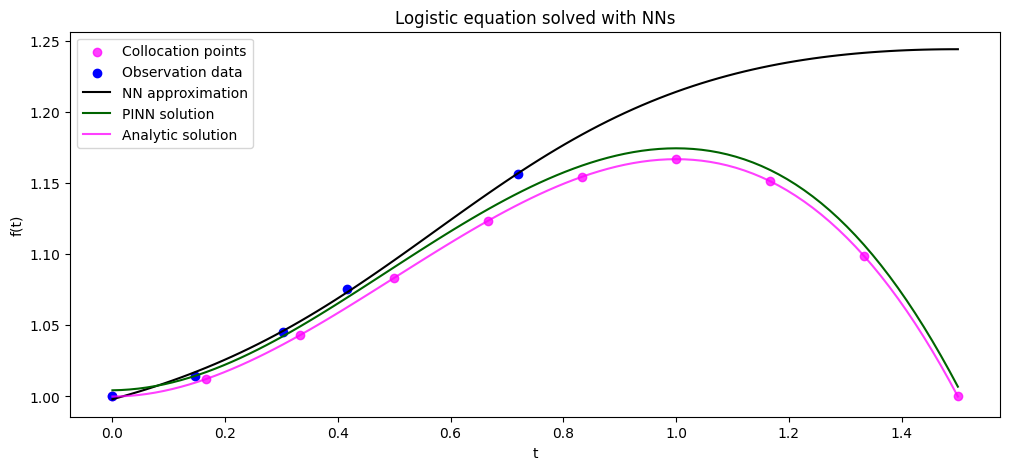

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(t.detach().numpy(), f_colloc, label="Collocation points", color="magenta", alpha=0.75)
ax.scatter(x_train.detach().numpy(), y_train.detach().numpy(), label="Observation data", color="blue")
ax.plot(x_eval.detach().numpy(), f_eval.detach().numpy(), label="NN approximation", color="black")
ax.plot(x_eval.detach().numpy(), f_PINN_eval.detach().numpy(), label="PINN solution", color="darkgreen")
ax.plot(x_eval.detach().numpy(), numeric_solution.y.T,
        label="Analytic solution", color="magenta", alpha=0.75)

ax.set(title="Logistic equation solved with NNs", xlabel="t", ylabel="f(t)")
ax.legend();

##3. Conclusions

The results demonstrate the advantages of Physics-Informed Neural Networks (PINNs) over traditional data-driven neural networks.

The traditional neural network can approximate the training data but struggles to generalize beyond the observed region. In contrast, the PINN produces a much closer approximation to the reference solution across the entire domain, including regions with limited or no training data.

This improvement comes from incorporating physical knowledge into the training process through the differential equation and the initial condition. As a result, the model learns not only from the available data but also from the mathematical laws governing the system.

This example highlights the potential of PINNs for solving scientific and engineering problems, particularly when experimental data is limited, expensive, or difficult to obtain.

Although the PINN does not perfectly match the reference solution, it demonstrates how combining data-driven learning with physical constraints can improve prediction accuracy and generalization.